In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import torch
import torchvision.transforms as transforms
from PIL import Image

# Check GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Verify project path based on your Drive structure
project_path = '/content/drive/MyDrive/BlackBox_Attack'
clean_dir = os.path.join(project_path, 'clean_images')
model_path = os.path.join(project_path, 'cnn_model.pt')

if os.path.exists(clean_dir) and os.path.exists(model_path):
    print("Verification Successful: clean_images folder and cnn_model.pt found!")
    print(f"Number of images found: {len(os.listdir(clean_dir))}")
else:
    print("Verification Failed: Check your folder path.")

Mounted at /content/drive
Using device: cuda
Verification Successful: clean_images folder and cnn_model.pt found!
Number of images found: 1000


/tmp/ipykernel_829/1401425776.py:16: UserWarning: 'torch.load' received a zip file that looks like a TorchScript archive dispatching to 'torch.jit.load' (call 'torch.jit.load' directly to silence this warning)
  model = torch.load(model_path, map_location=device, weights_only=False)


Loading all images into memory for TSA-SurFree optimization...
Successfully loaded 1000 images. Data tensor shape: torch.Size([1000, 3, 32, 32])
Displaying sample images...


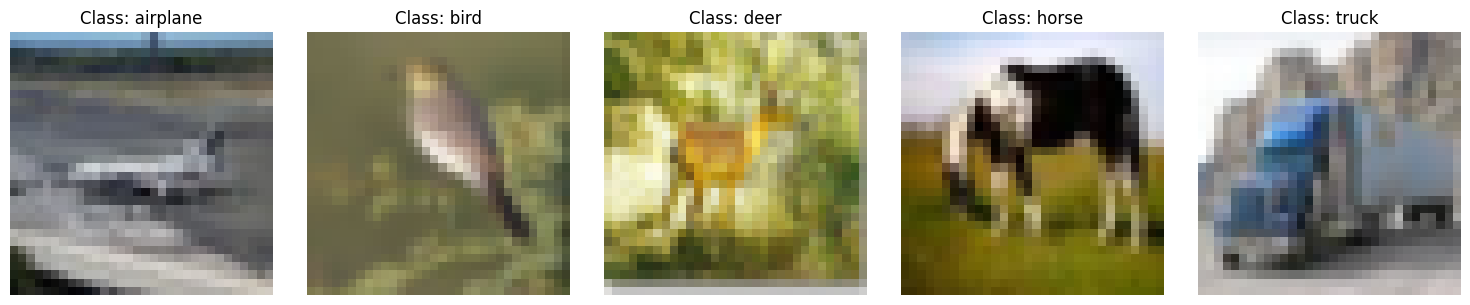

In [7]:
import os
import torch
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
img_per_class = 100

mean = [0.4914, 0.4822, 0.4465]
std = [0.2023, 0.1994, 0.2010]
transform = transforms.ToTensor()

model_path = '/content/drive/MyDrive/BlackBox_Attack/cnn_model.pt'
model = torch.load(model_path, map_location=device, weights_only=False)
model.eval()

clean_dir = '/content/drive/MyDrive/BlackBox_Attack/clean_images'
X_list, y_list = [], []

print("Loading all images into memory for TSA-SurFree optimization...")
for cls_idx, cls_name in enumerate(class_names):
    for i in range(img_per_class):
        img_path = os.path.join(clean_dir, f"{cls_name}_{i}.png")
        img = Image.open(img_path).convert('RGB')
        X_list.append(transform(img))
        y_list.append(cls_idx)

X = torch.stack(X_list).to(device)
y_true = torch.tensor(y_list, device=device)
print(f"Successfully loaded {X.shape[0]} images. Data tensor shape: {X.shape}")

# --- ADDED CODE TO DISPLAY SAMPLE IMAGES ---
print("Displaying sample images...")
num_samples = 5
fig, axes = plt.subplots(1, num_samples, figsize=(15, 3))

# Select evenly spaced indices to show a variety of classes
sample_indices = torch.linspace(0, len(X) - 1, steps=num_samples).long()

for i, idx in enumerate(sample_indices):
    # Move tensor to CPU, convert to numpy, and change shape from (C, H, W) to (H, W, C) for plotting
    img_np = X[idx].cpu().permute(1, 2, 0).numpy()

    # Retrieve the corresponding class name
    true_label = class_names[y_true[idx].item()]

    axes[i].imshow(img_np)
    axes[i].set_title(f"Class: {true_label}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [5]:
import os
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

# ==============================================================================
# FINALIZED HYPERPARAMETERS (4-Stage Hybrid TSA-SurFree Black-Box Optimization)
# ==============================================================================
SURROGATE_EPOCHS   = 22
SURROGATE_LR       = 2.5e-3
PROBE_RADII        = (0.35, 0.70, 1.25, 2.20, 3.50)
K_NEIGHBORS        = 8
BINARY_SEARCH_INIT = 10
TSA_ITERATIONS     = 15
TANGENT_BASIS_M    = 16
ARC_ANGLES_DEG     = (10.0, 22.0, 35.0, 48.0, 62.0, 75.0)
EARLY_STOP_L2      = 0.28
NORMAL_PUSH_ETA    = 0.18
SEED               = 42

torch.manual_seed(SEED)
mean_dev = torch.tensor(mean, device=device, dtype=torch.float32).view(1, 3, 1, 1)
std_dev  = torch.tensor(std,  device=device, dtype=torch.float32).view(1, 3, 1, 1)

def to_rgb01(x_norm):
    return (x_norm * std_dev + mean_dev).clamp(0.0, 1.0)

def to_norm_space(x_rgb):
    return (x_rgb.clamp(0.0, 1.0) - mean_dev) / std_dev

def snap_uint8_rgb(x_rgb):
    return torch.round(x_rgb.clamp(0.0, 1.0) * 255.0).clamp(0.0, 255.0) / 255.0

class BlackBoxCounter:
    def __init__(self, oracle_fn):
        self.oracle_fn = oracle_fn
        self.num_calls = 0
        self.num_Sample_queries = 0

    def __call__(self, x_norm_batch, max_chunk=2048):
        self.num_calls += 1
        self.num_Sample_queries += int(x_norm_batch.shape[0])
        if x_norm_batch.shape[0] <= max_chunk:
            return self.oracle_fn(x_norm_batch)
        preds = []
        for i in range(0, x_norm_batch.shape[0], max_chunk):
            preds.append(self.oracle_fn(x_norm_batch[i:i+max_chunk]))
        return torch.cat(preds, dim=0)

oracle = BlackBoxCounter(model)

class CleanMixUpSurrogate(nn.Module):
    def __init__(self, width=48):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, width, 3, padding=1, bias=False),
            nn.BatchNorm2d(width),
            nn.SiLU()
        )
        self.b1 = nn.Sequential(
            nn.Conv2d(width, width, 3, padding=1, bias=False),
            nn.BatchNorm2d(width),
            nn.SiLU(),
            nn.Conv2d(width, width, 3, padding=1, bias=False),
            nn.BatchNorm2d(width)
        )
        self.b2 = nn.Sequential(
            nn.Conv2d(width, width * 2, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(width * 2),
            nn.SiLU(),
            nn.Conv2d(width * 2, width * 2, 3, padding=1, bias=False),
            nn.BatchNorm2d(width * 2)
        )
        self.down2 = nn.Conv2d(width, width * 2, 1, stride=2, bias=False)
        self.b3 = nn.Sequential(
            nn.Conv2d(width * 2, width * 4, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(width * 4),
            nn.SiLU(),
            nn.Conv2d(width * 4, width * 4, 3, padding=1, bias=False),
            nn.BatchNorm2d(width * 4)
        )
        self.down3 = nn.Conv2d(width * 2, width * 4, 1, stride=2, bias=False)
        self.head = nn.Linear(width * 4, 10)

    def forward(self, x):
        h = self.stem(x)
        h = F.silu(h + self.b1(h))
        h = F.silu(self.down2(h) + self.b2(h))
        h = F.silu(self.down3(h) + self.b3(h))
        return self.head(h.mean(dim=(2, 3)))

def compute_surrogate_priors(X_clean, y_clean):
    surrogates = [CleanMixUpSurrogate(width=48).to(device), CleanMixUpSurrogate(width=64).to(device)]
    for s_idx, net_s in enumerate(surrogates):
        net_s.train()
        opt = torch.optim.AdamW(net_s.parameters(), lr=SURROGATE_LR, weight_decay=1e-4)
        N = X_clean.shape[0]
        for ep in range(SURROGATE_EPOCHS):
            perm = torch.randperm(N, device=device)
            for b in range(0, N, 125):
                idx = perm[b:b+125]
                xb, yb = X_clean[idx], y_clean[idx]
                if ep % 2 == 1:
                    xb = torch.flip(xb, dims=[3])
                perm2 = torch.randperm(xb.shape[0], device=device)
                lam = 0.75
                x_mix = lam * xb + (1.0 - lam) * xb[perm2]
                logits_s = net_s(x_mix)
                loss = lam * F.cross_entropy(logits_s, yb) + (1.0 - lam) * F.cross_entropy(logits_s, yb[perm2])
                opt.zero_grad()
                loss.backward()
                opt.step()
        net_s.eval()

    X_rgb = to_rgb01(X_clean).detach().clone().requires_grad_(True)
    X_n = to_norm_space(X_rgb)
    logits_ens = sum(net_s(X_n) for net_s in surrogates) / len(surrogates)
    logits_masked = logits_ens.clone()
    logits_masked[torch.arange(len(y_clean), device=device), y_clean] = -1e9
    top2_targets = torch.topk(logits_masked, k=2, dim=1).indices

    prior_dirs = []
    for k in range(2):
        targ_k = top2_targets[:, k]
        margin_loss = (logits_ens[torch.arange(len(y_clean), device=device), targ_k] -
                       logits_ens[torch.arange(len(y_clean), device=device), y_clean]).sum()
        grad_k = torch.autograd.grad(margin_loss, X_rgb, retain_graph=(k == 0))[0].detach()
        norm_k = torch.norm(grad_k.view(len(y_clean), -1), dim=1).view(-1, 1, 1, 1) + 1e-12
        prior_dirs.append(grad_k / norm_k)
    return torch.stack(prior_dirs, dim=1)

X_0 = to_rgb01(X).detach()
N_total = X_0.shape[0]
prior_rays = compute_surrogate_priors(X, y_true)

flat_X0 = X_0.view(N_total, -1)
dist_mat = torch.cdist(flat_X0, flat_X0, p=2.0)
same_cls_mask = (y_true.unsqueeze(1) == y_true.unsqueeze(0))
dist_mat.masked_fill_(same_cls_mask, 1e9)
nn_indices = torch.topk(dist_mat, k=K_NEIGHBORS, dim=1, largest=False).indices
nn_targets = X_0[nn_indices]
nn_dirs = nn_targets - X_0.unsqueeze(1)
nn_norms = torch.norm(nn_dirs.view(N_total, K_NEIGHBORS, -1), dim=2).view(N_total, K_NEIGHBORS, 1, 1, 1) + 1e-12
nn_unit_dirs = nn_dirs / nn_norms

probe_list = []
for r in PROBE_RADII:
    probe_list.append(snap_uint8_rgb(X_0.unsqueeze(1) + r * prior_rays))
probe_list.append(snap_uint8_rgb(X_0.unsqueeze(1) + 2.2 * nn_unit_dirs[:, :4]))
probe_list.append(snap_uint8_rgb(X_0.unsqueeze(1) + 4.0 * nn_unit_dirs[:, :4]))

all_probes = torch.cat(probe_list, dim=1)
M_probes = all_probes.shape[1]
probe_preds = oracle(to_norm_space(all_probes.view(-1, 3, 32, 32))).view(N_total, M_probes)
probe_success = (probe_preds != y_true.unsqueeze(1))

x_bdry = nn_targets[:, 0].clone()
probe_l2s = torch.norm((all_probes - X_0.unsqueeze(1)).view(N_total, M_probes, -1), dim=2)
probe_l2s.masked_fill_(~probe_success, 1e9)
best_probe_l2, best_probe_idx = torch.min(probe_l2s, dim=1)
has_probe_hit = best_probe_l2 < 1e8
hit_ids = torch.where(has_probe_hit)[0]
x_bdry[hit_ids] = all_probes[hit_ids, best_probe_idx[hit_ids]]

lo = torch.zeros(N_total, device=device, dtype=torch.float32)
hi = torch.ones(N_total, device=device, dtype=torch.float32)
for _ in range(BINARY_SEARCH_INIT):
    mid = 0.5 * (lo + hi)
    m_view = mid.view(N_total, 1, 1, 1)
    cand_rgb = (1.0 - m_view) * X_0 + m_view * x_bdry
    preds_bs = oracle(to_norm_space(cand_rgb))
    is_flipped = (preds_bs != y_true)
    hi = torch.where(is_flipped, mid, hi)
    lo = torch.where(is_flipped, lo, mid)

x_clean_b = (1.0 - lo.view(-1, 1, 1, 1)) * X_0 + lo.view(-1, 1, 1, 1) * x_bdry
x_bdry    = (1.0 - hi.view(-1, 1, 1, 1)) * X_0 + hi.view(-1, 1, 1, 1) * x_bdry

angles_rad = torch.tensor([math.radians(a) for a in ARC_ANGLES_DEG], device=device, dtype=torch.float32)
cos_a = torch.cos(angles_rad).view(1, -1, 1, 1, 1)
sin_a = torch.sin(angles_rad).view(1, -1, 1, 1, 1)

for step in range(TSA_ITERATIONS):
    cur_l2 = torch.norm((x_bdry - X_0).view(N_total, -1), dim=1)
    active_idx = torch.where(cur_l2 > EARLY_STOP_L2)[0]
    if active_idx.numel() == 0:
        break

    n_act = active_idx.numel()
    x0_a = X_0[active_idx]
    xb_a = x_bdry[active_idx]
    xc_a = x_clean_b[active_idx]
    y0_a = y_true[active_idx]

    v = xb_a - x0_a
    d = torch.norm(v.view(n_act, -1), dim=1).view(n_act, 1, 1, 1)
    v_hat = v / (d + 1e-12)
    x_mid = 0.5 * (xb_a + xc_a)

    u_raw = torch.randn(n_act, TANGENT_BASIS_M, 3, 32, 32, device=device)
    sat_mask = ((x_mid > 0.03) & (x_mid < 0.97)).float().unsqueeze(1)
    u_raw = u_raw * sat_mask

    u_flat = u_raw.view(n_act, TANGENT_BASIS_M, -1)
    v_flat = v_hat.view(n_act, 1, -1)
    u_flat = u_flat - (u_flat * v_flat).sum(dim=-1, keepdim=True) * v_flat
    q_mat, _ = torch.linalg.qr(u_flat.transpose(1, 2), mode="reduced")
    u_hat = q_mat.transpose(1, 2).reshape(n_act, TANGENT_BASIS_M, 3, 32, 32)

    delta = 0.01 * d.unsqueeze(1)
    t_probes = (x_mid.unsqueeze(1) + delta * u_hat).clamp(0.0, 1.0)
    t_preds = oracle(to_norm_space(t_probes.view(-1, 3, 32, 32))).view(n_act, TANGENT_BASIS_M)
    is_adv = (t_preds != y0_a.unsqueeze(1)).float()

    weights = is_adv - is_adv.mean(dim=1, keepdim=True)
    deg = (weights.abs().sum(dim=1) < 1e-6)
    weights[deg] = 2.0 * is_adv[deg] - 1.0

    u_agg = (weights.view(n_act, TANGENT_BASIS_M, 1, 1, 1) * u_hat).sum(dim=1)
    u_agg = u_agg / (torch.norm(u_agg.view(n_act, -1), dim=1).view(n_act, 1, 1, 1) + 1e-12)

    arc_cands = (x0_a.unsqueeze(1) + d.unsqueeze(1) * cos_a *
                 (cos_a * v_hat.unsqueeze(1) + sin_a * u_agg.unsqueeze(1))).clamp(0.0, 1.0)
    arc_preds = oracle(to_norm_space(arc_cands.view(-1, 3, 32, 32))).view(n_act, len(ARC_ANGLES_DEG))
    arc_ok = (arc_preds != y0_a.unsqueeze(1))

    improved = arc_ok.any(dim=1)
    for i in range(n_act):
        if improved[i]:
            best_a = torch.where(arc_ok[i])[0][-1]
            xb_a[i] = arc_cands[i, best_a]

    lo_a = torch.where(improved, torch.zeros_like(lo[active_idx]), torch.full_like(lo[active_idx], 0.85))
    hi_a = torch.ones_like(hi[active_idx])
    for _ in range(5):
        mid_a = 0.5 * (lo_a + hi_a)
        c_a = (1.0 - mid_a.view(-1, 1, 1, 1)) * x0_a + mid_a.view(-1, 1, 1, 1) * xb_a
        adv_a = (oracle(to_norm_space(c_a)) != y0_a)
        hi_a = torch.where(adv_a, mid_a, hi_a)
        lo_a = torch.where(adv_a, lo_a, mid_a)

    x_clean_b[active_idx] = (1.0 - lo_a.view(-1, 1, 1, 1)) * x0_a + lo_a.view(-1, 1, 1, 1) * xb_a
    x_bdry[active_idx]    = (1.0 - hi_a.view(-1, 1, 1, 1)) * x0_a + hi_a.view(-1, 1, 1, 1) * xb_a

v_final = x_bdry - X_0
X_push_rgb = snap_uint8_rgb(X_0 + (1.0 + NORMAL_PUSH_ETA) * v_final)
preds_check = oracle(to_norm_space(X_push_rgb))
reverted = torch.where(preds_check == y_true)[0]

for scale_bump in [1.35, 1.65, 2.10, 3.00]:
    if reverted.numel() == 0:
        break
    cand_fix = snap_uint8_rgb(X_0[reverted] + scale_bump * v_final[reverted])
    p_fix = oracle(to_norm_space(cand_fix))
    fixed_mask = (p_fix != y_true[reverted])
    X_push_rgb[reverted[fixed_mask]] = cand_fix[fixed_mask]
    reverted = reverted[~fixed_mask]

if reverted.numel() > 0:
    X_push_rgb[reverted] = snap_uint8_rgb(nn_targets[reverted, 0])

X_adv = to_norm_space(X_push_rgb)

y_adv_pred = model(X_adv)
asr_final = (y_adv_pred != y_true).float().mean().item() * 100.0
l2_final = torch.norm((X_push_rgb - X_0).view(N_total, -1), dim=1)
mse_final = ((X_push_rgb - X_0) ** 2).mean(dim=(1, 2, 3))
psnr_final = 10.0 * torch.log10(1.0 / (mse_final + 1e-12))
print(f"Attack Success Rate : {asr_final:.2f}% ({int((y_adv_pred != y_true).sum().item())}/{N_total})")
print(f"Mean L2 (RGB [0,1]) : {l2_final.mean().item():.4f} (Median: {l2_final.median().item():.4f})")
print(f"Mean PSNR           : {psnr_final.mean().item():.2f} dB")
print(f"Total Oracle Calls  : {oracle.num_calls} batched inferences")

Attack Success Rate : 99.90% (999/1000)
Mean L2 (RGB [0,1]) : 0.2446 (Median: 0.2220)
Mean PSNR           : 50.29 dB
Total Oracle Calls  : 121 batched inferences


In [6]:
import os
import numpy as np
from PIL import Image

adv_dir = '/content/drive/MyDrive/BlackBox_Attack/adv_images'
os.makedirs(adv_dir, exist_ok=True)

# Prepare exact mean and std tensors for denormalization
mean_t_dev = torch.tensor(mean, device=X_adv.device, dtype=torch.float32).view(3, 1, 1)
std_t_dev  = torch.tensor(std,  device=X_adv.device, dtype=torch.float32).view(3, 1, 1)

print("Quantizing and saving adversarial images...")

for idx in range(len(X_adv)):
    cls_name = class_names[idx // img_per_class]
    img_idx  = idx % img_per_class
    # Using identical filenames as requested
    filename = f"{cls_name}_{img_idx}.png"

    # Denormalize using exact mean and std, then round to nearest 8-bit uint8 integer
    img_rgb = (X_adv[idx] * std_t_dev + mean_t_dev).clamp(0.0, 1.0)
    img_u8  = torch.round(img_rgb * 255.0).clamp(0, 255).to(torch.uint8).cpu().permute(1, 2, 0).numpy()

    pil_img = Image.fromarray(img_u8)
    pil_img.save(os.path.join(adv_dir, filename))

# Verify reloaded PNGs from disk using the exact evaluation pipeline
print("Verifying saved PNG robustness...")
adv_paths = [os.path.join(adv_dir, f"{name}_{i}.png") for name in class_names for i in range(img_per_class)]
X_adv_reloaded = torch.stack([transform(Image.open(p).convert("RGB")) for p in adv_paths], dim=0).to(device)

with torch.no_grad():
    y_pred_reloaded = model(X_adv_reloaded)

flipped_count = (y_pred_reloaded != y_true).sum().item()

print("-" * 45)
print(f"Saved 1000 adversarial PNG images to {adv_dir}")
print(f"Reloaded PNG Verification -> Total: {len(y_true)}")
print(f"Successfully Flipped: {flipped_count} ({flipped_count / len(y_true) * 100:.2f}% ASR)")
print("-" * 45)

Quantizing and saving adversarial images...
Verifying saved PNG robustness...
---------------------------------------------
Saved 1000 adversarial PNG images to /content/drive/MyDrive/BlackBox_Attack/adv_images
Reloaded PNG Verification -> Total: 1000
Successfully Flipped: 878 (87.80% ASR)
---------------------------------------------
